In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

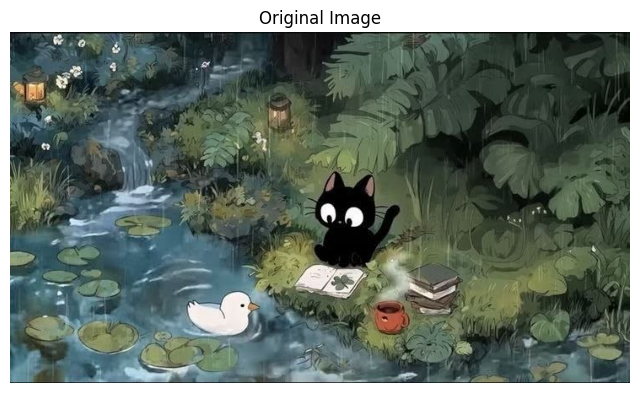

In [3]:
image = cv2.imread("/content/wall2.jpg")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [4]:
print("Image Shape:", image.shape)
print("Height:", image.shape[0])
print("Width:", image.shape[1])
print("Channels:", image.shape[2])

Image Shape: (416, 735, 3)
Height: 416
Width: 735
Channels: 3


In [5]:
pixels = image.reshape(-1, 3)

print("Original Image Shape:", image.shape)
print("Pixels Shape:", pixels.shape)

Original Image Shape: (416, 735, 3)
Pixels Shape: (305760, 3)


In [6]:
k = 5

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans.fit(pixels)

KMeans(n_clusters=5, n_init=10, random_state=42)

In [7]:
labels = kmeans.labels_

print("Cluster Labels:", labels)
print("Number of Clusters:", len(np.unique(labels)))

Cluster Labels: [4 4 4 ... 4 4 4]
Number of Clusters: 5


In [12]:
centers = kmeans.cluster_centers_

print("Cluster Centers:")
print(centers)

Cluster Centers:
[[ 82.89946557 100.62874797  89.25310152]
 [ 52.90402452  66.51883216  57.05303423]
 [119.10253698 136.35967275 120.46085447]
 [208.48124509 214.64493323 212.70748233]
 [ 20.65313812  28.87436159  23.40186131]]


In [13]:
new_pixels = centers[labels]

new_pixels = new_pixels.astype(np.uint8)

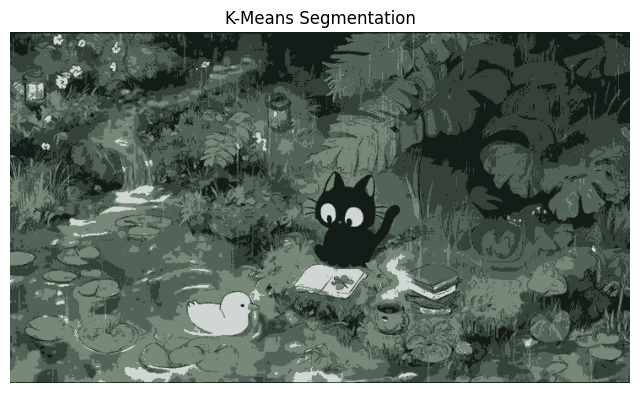

In [14]:
segmented_image = new_pixels.reshape(image.shape)

plt.figure(figsize=(8, 6))
plt.imshow(segmented_image)
plt.title("K-Means Segmentation")
plt.axis("off")
plt.show()

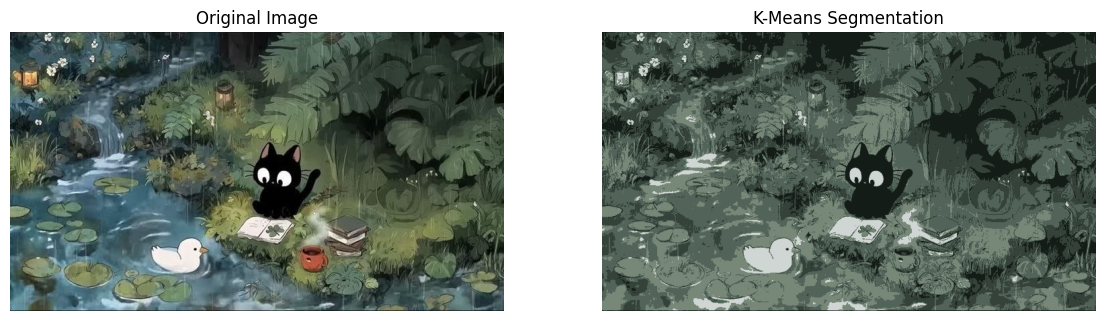

In [15]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented_image)
plt.title("K-Means Segmentation")
plt.axis("off")

plt.show()